In [2]:
import pandas as pd

In [17]:
cancer_data=pd.read_csv(r'F:\Cancer AI Analyst\data\structured\raw\global_cancer_patients_2015_2024.csv')
print(cancer_data.shape)
cancer_data.head()

(50000, 15)


,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,PT0000000,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92
1,PT0000001,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65
2,PT0000002,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84
3,PT0000003,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12
4,PT0000004,43,Female,Brazil,2017,5.1,2.8,2.3,6.7,0.5,Skin,Stage III,77977.12,2.9,3.62


In [4]:
cancer_data.isnull().sum()

Patient_ID               0
Age                      0
Gender                   0
Country_Region           0
Year                     0
Genetic_Risk             0
Air_Pollution            0
Alcohol_Use              0
Smoking                  0
Obesity_Level            0
Cancer_Type              0
Cancer_Stage             0
Treatment_Cost_USD       0
Survival_Years           0
Target_Severity_Score    0
dtype: int64

In [5]:
cancer_data.duplicated().sum()

np.int64(0)

In [6]:
cancer_data.dtypes

Patient_ID                object
Age                        int64
Gender                    object
Country_Region            object
Year                       int64
Genetic_Risk             float64
Air_Pollution            float64
Alcohol_Use              float64
Smoking                  float64
Obesity_Level            float64
Cancer_Type               object
Cancer_Stage              object
Treatment_Cost_USD       float64
Survival_Years           float64
Target_Severity_Score    float64
dtype: object

## Total Row of the Patient_ID data

In [18]:
cancer_data["Patient_ID"].nunique()

50000

## Total Row of Our Datasets

In [15]:
len(cancer_data)

50000

## Patient_ID=Total Row ----> 50000 then there is no need of Patient_ID and now we can drop the Patient_ID

In [19]:
cancer_data=cancer_data.drop(columns=['Patient_ID'])


In [13]:
cancer_data.head()

,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92
1,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65
2,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84
3,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12
4,43,Female,Brazil,2017,5.1,2.8,2.3,6.7,0.5,Skin,Stage III,77977.12,2.9,3.62


## Checking the numericals columns

In [20]:
numerical_cols=cancer_data.select_dtypes(
    include=["int64", "float64"]
).columns
numerical_cols

Index(['Age', 'Year', 'Genetic_Risk', 'Air_Pollution', 'Alcohol_Use',
       'Smoking', 'Obesity_Level', 'Treatment_Cost_USD', 'Survival_Years',
       'Target_Severity_Score'],
      dtype='object')

## Creating the box plot to show the outliers

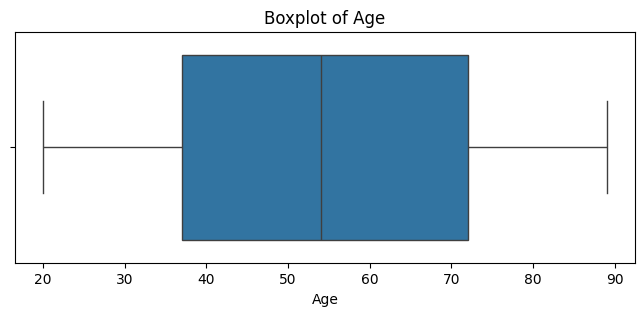

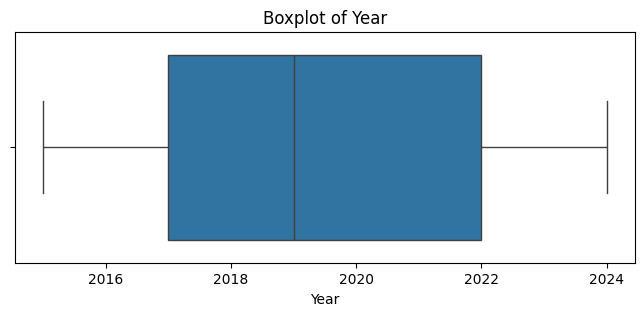

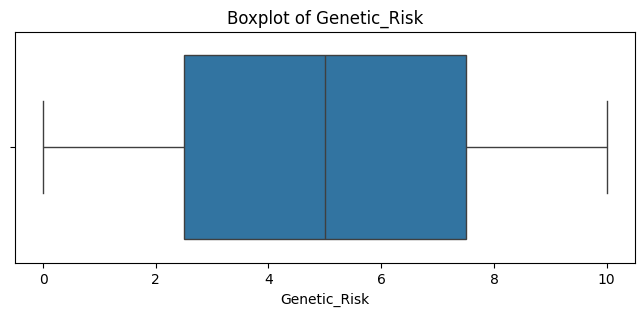

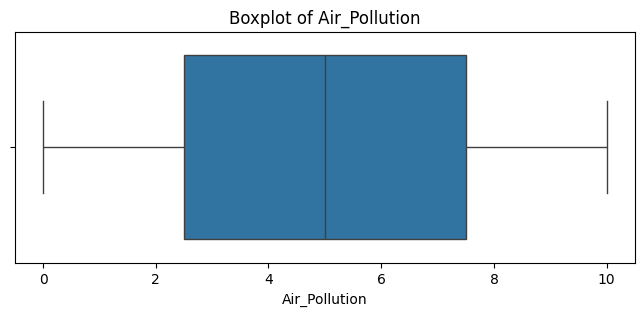

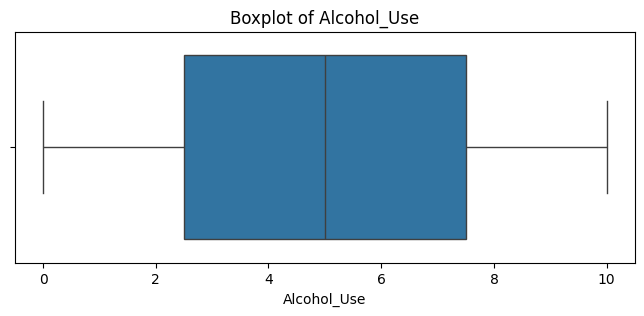

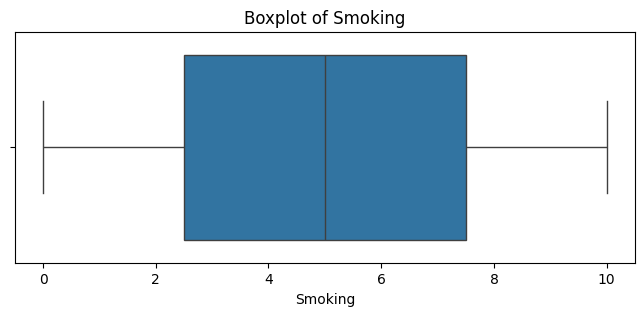

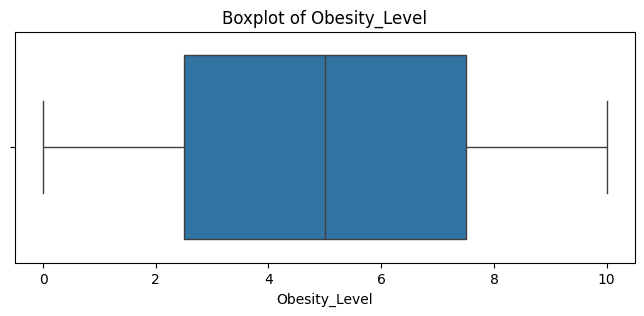

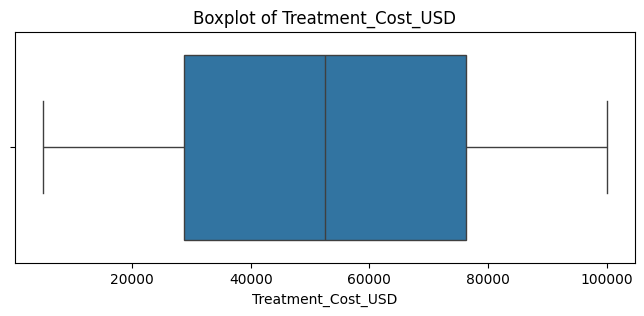

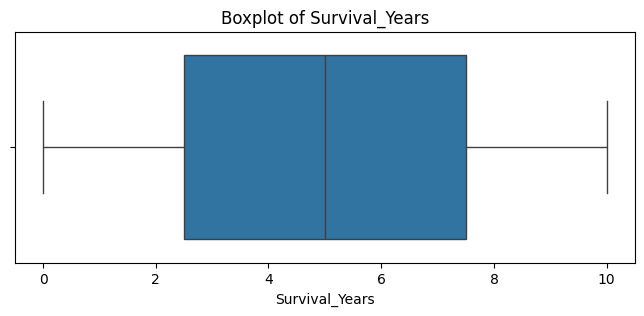

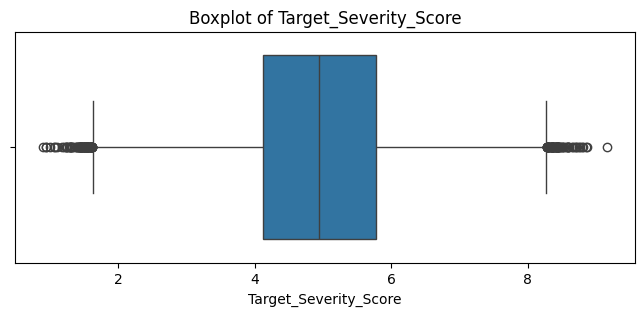

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
for col in numerical_cols:
    plt.figure(figsize=(8,3))
    sns.boxplot(x=cancer_data[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

## Counting Of Outliers by Inter Quartile Range (IQR) Method

In [23]:
def count_outliers(df, column):
    Q1=df[column].quantile(0.25)
    Q3=df[column].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    outliers=df[
        (df[column]<lower)
        |
        (df[column]>upper)
    ]
    return len(outliers)

In [24]:
for col in numerical_cols:
     print(
        f"{col}: {count_outliers(cancer_data, col)}"
    )

Age: 0
Year: 0
Genetic_Risk: 0
Air_Pollution: 0
Alcohol_Use: 0
Smoking: 0
Obesity_Level: 0
Treatment_Cost_USD: 0
Survival_Years: 0
Target_Severity_Score: 151


In [25]:
Q1=cancer_data["Target_Severity_Score"].quantile(0.25)
Q3=cancer_data["Target_Severity_Score"].quantile(0.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
outliers=cancer_data[
    (cancer_data["Target_Severity_Score"] < lower)
    |
    (cancer_data["Target_Severity_Score"] > upper)
]
outliers["Target_Severity_Score"].describe()

count    151.000000
mean       4.648079
std        3.522990
min        0.900000
25%        1.460000
50%        1.610000
75%        8.410000
max        9.160000
Name: Target_Severity_Score, dtype: float64

## Category Consistency Check

In [27]:
for col in ["Gender","Cancer_Type","Cancer_Stage"]:
    print(col)
    print(cancer_data[col].unique())

Gender
['Male' 'Female' 'Other']
Cancer_Type
['Lung' 'Leukemia' 'Breast' 'Colon' 'Skin' 'Cervical' 'Prostate' 'Liver']
Cancer_Stage
['Stage III' 'Stage 0' 'Stage II' 'Stage I' 'Stage IV']


## Save the Data

In [28]:
cancer_data.to_csv(
    "../data/structured/processed/cancer_cleaned.csv",
    index=False
)